# EDA - Análise de Exploratória dos Dados

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

df = pd.read_csv(r"../data/processado/jogador_temporada.csv")

## Estatísticas descritivas: Variáveis numéricas

In [9]:
df.select_dtypes(include="number").drop(columns="player_id").describe().T

,count,mean,std,min,25%,50%,75%,max
season,507.0,2.024323e+03,4.682629e-01,2024.0,2024.000000,2.024000e+03,2.025000e+03,2.025000e+03
gols,507.0,2.086785e+00,2.869418e+00,0.0,0.000000,1.000000e+00,3.000000e+00,2.100000e+01
assistencias,507.0,1.372781e+00,1.794009e+00,0.0,0.000000,1.000000e+00,2.000000e+00,1.400000e+01
minutos_jogados,507.0,1.588872e+03,6.077255e+02,900.0,1122.500000,1.361000e+03,1.954000e+03,3.420000e+03
cartoes_amarelos,507.0,3.656805e+00,2.545353e+00,0.0,2.000000,3.000000e+00,5.000000e+00,1.400000e+01
cartoes_vermelhos,507.0,1.775148e-01,4.170849e-01,0.0,0.000000,0.000000e+00,0.000000e+00,2.000000e+00
jogos_disputados,507.0,2.178895e+01,7.442589e+00,10.0,15.000000,1.900000e+01,2.800000e+01,3.800000e+01
gols_por90,507.0,1.220047e-01,1.581825e-01,0.0,0.000000,7.142857e-02,1.792857e-01,1.138040e+00
assistencias_por90,507.0,8.088594e-02,1.026952e-01,0.0,0.000000,5.632040e-02,1.228460e-01,6.081081e-01
cartoes_amarelos_por90,507.0,2.108144e-01,1.331597e-01,0.0,0.104571,1.939655e-01,2.900888e-01,7.484407e-01


- Altura mínima de 18 cm (pode ser erro de digitação)

## Estatísticas descritivas: variáveis categóricas

In [10]:
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
temporada_completa,507,2,True,343
clube_temporada,507,24,Sport Club Internacional,30
name,507,376,Gabriel,4
position,507,4,Defender,202
sub_position,507,10,Centre-Back,108
foot,507,3,right,347
date_of_birth,507,374,1993-03-24 00:00:00,4
country_of_citizenship,507,17,Brazil,358
current_club_name,505,53,Esporte Clube Vitória,33
contract_expiration_date,495,21,2026-12-31 00:00:00,135


## Verificação dos nulos

In [11]:
nulos = df.isna().sum()
tabela_nulos = pd.DataFrame({"nulos": nulos, "% do total": (nulos / len(df) * 100).round(1)})
tabela_nulos[tabela_nulos["nulos"] > 0].sort_values(by="nulos", ascending=False)

,nulos,% do total
market_value_in_eur,32,6.3
contract_expiration_date,12,2.4
current_club_name,2,0.4


Só três variáveis têm valores nulos:

- `market_value_in_eur` (32): é o alvo, então não dá para imputar. Essas linhas serão retiradas da base de modelagem.
- `contract_expiration_date` (12): será preenchida com a mediana calculada só no treino. Também será criada uma variável indicadora (`sem_info_contrato`) para marcar quem não tinha a informação.
- `current_club_name` (2): não será usada no modelo, porque é o clube atual e não o da temporada. Em seu lugar entra o clube em que o jogador atuou na temporada.

## Distribuição do valor de mercado (escala bruta vs. log)

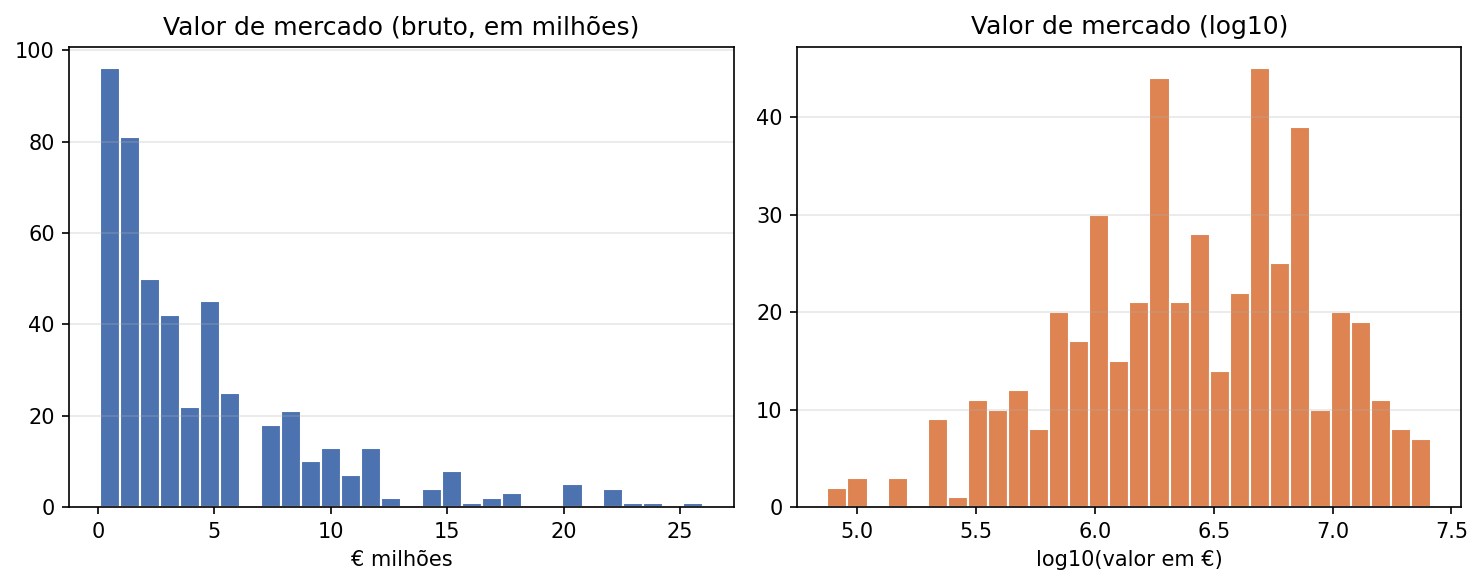

In [12]:
os.makedirs("../figuras", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=150)

axes[0].hist(df["market_value_in_eur"] / 1e6, bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_title("Valor de mercado (bruto, em milhões)")
axes[0].set_xlabel("€ milhões")

axes[1].hist(np.log10(df["market_value_in_eur"]), bins=30, color="#DD8452", edgecolor="white")
axes[1].set_title("Valor de mercado (log10)")
axes[1].set_xlabel("log10(valor em €)")

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig("../figuras/eda_distribuicao_valor.png")
plt.show()

- O valor de mercado tem distribuição assimétrica à direita
- A transformação logarítmica aproxima a distribuição de uma forma simétrica

## Relação entre desempenho e valor por posição

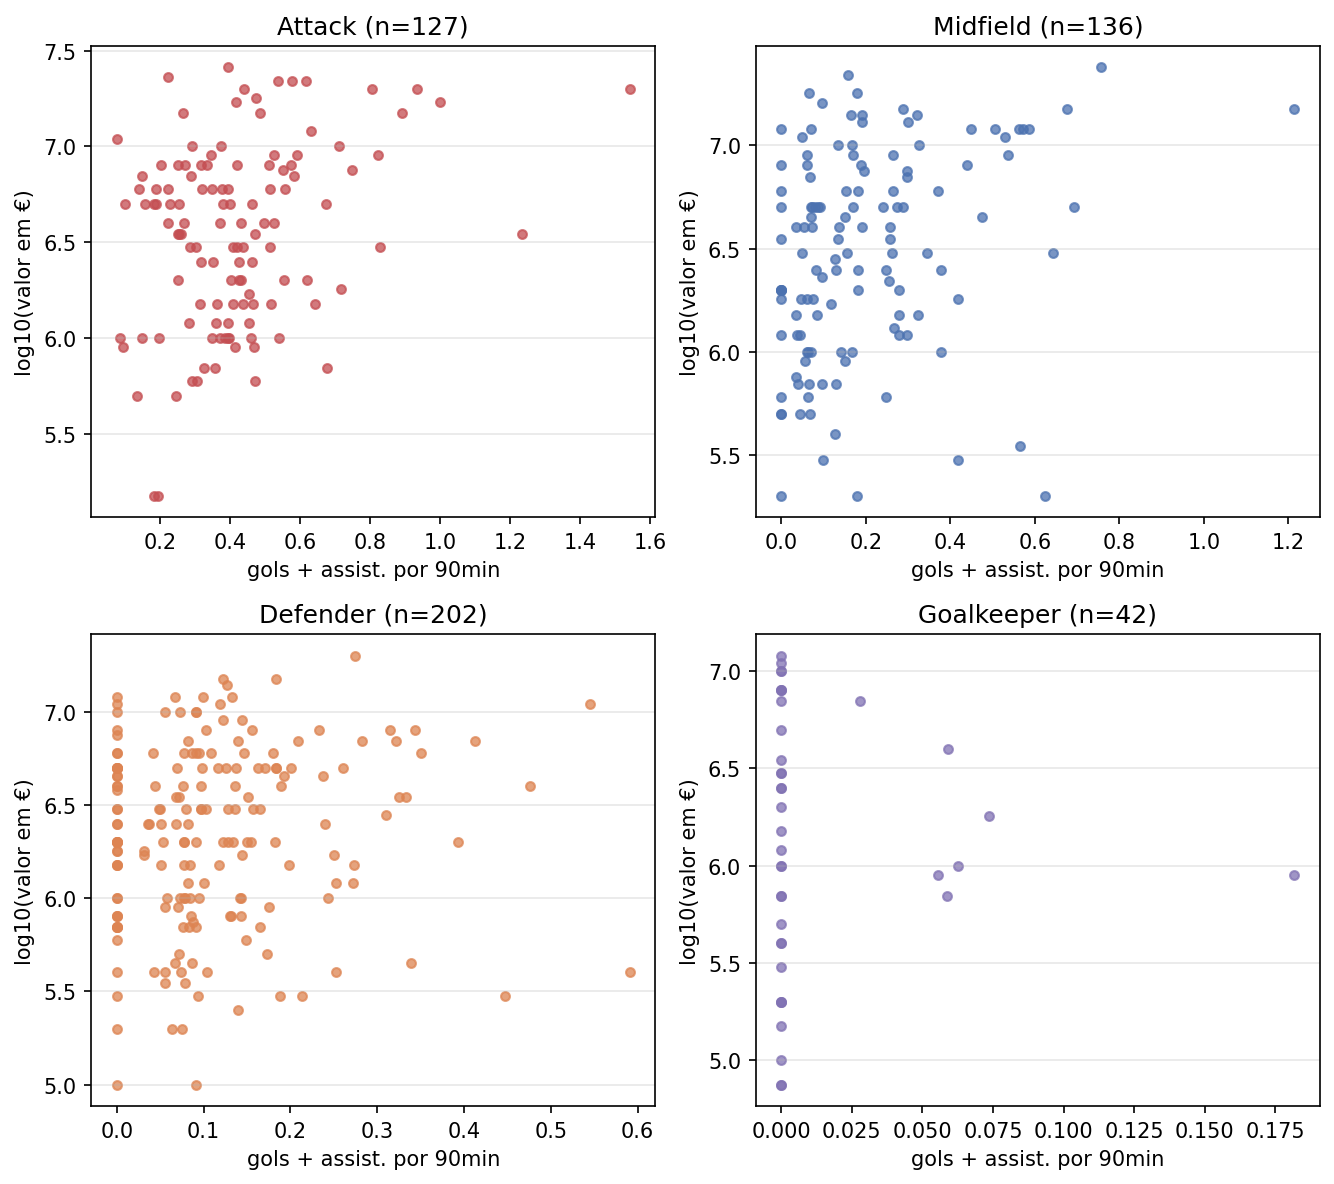

In [13]:
cores = {"Attack": "#C44E52", "Midfield": "#4C72B0", "Defender": "#DD8452", "Goalkeeper": "#8172B3"}

fig, axes = plt.subplots(2, 2, figsize=(9, 8), dpi=150)

for ax, pos in zip(axes.flat, cores):
    sub = df[df["position"] == pos]
    ax.scatter(
        sub["gols_por90"] + sub["assistencias_por90"],
        np.log10(sub["market_value_in_eur"]),
        s=18, color=cores[pos], alpha=0.75,
    )
    ax.set_title(f"{pos} (n={len(sub)})")
    ax.set_xlabel("gols + assist. por 90min")
    ax.set_ylabel("log10(valor em €)")
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig("../figuras/eda_correlacao_por_posicao.png")
plt.show()

- Atacantes e meias: a tendência é levemente positiva (um pouco mais nos meias), mas com muita dispersão. 
- Defensores: relação muito fraca. A maioria tem poucos gols e assistências por 90 min.
- Goleiros (n=42): quase todos em zero, então essa métrica não explica o valor deles.

## Correlações com o valor de mercado

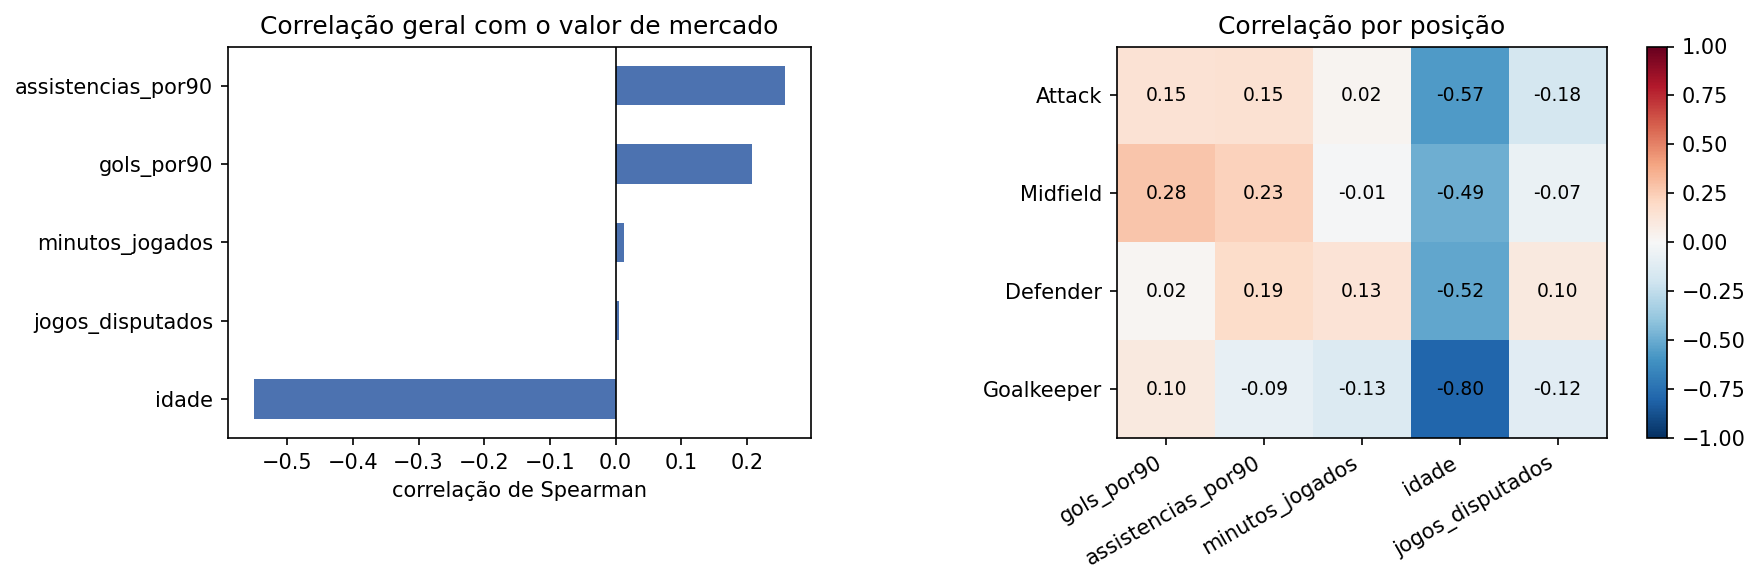

In [14]:
perf_cols = ["gols_por90", "assistencias_por90", "minutos_jogados", "idade", "jogos_disputados"]
cols = perf_cols + ["market_value_in_eur"]
ordem = ["Attack", "Midfield", "Defender", "Goalkeeper"]

corr = df[cols].corr(method="spearman")["market_value_in_eur"].drop("market_value_in_eur")
corr_by_pos = (
    df.groupby("position")[cols]
    .apply(lambda g: g.corr(method="spearman")["market_value_in_eur"].drop("market_value_in_eur"))
    .loc[ordem]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=150, gridspec_kw={"width_ratios": [1, 1.4]})

corr.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Correlação geral com o valor de mercado")
axes[0].set_xlabel("correlação de Spearman")

im = axes[1].imshow(corr_by_pos, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(perf_cols)), perf_cols, rotation=30, ha="right")
axes[1].set_yticks(range(len(ordem)), ordem)
axes[1].set_title("Correlação por posição")
for i in range(corr_by_pos.shape[0]):
    for j in range(corr_by_pos.shape[1]):
        axes[1].text(j, i, f"{corr_by_pos.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=axes[1])

fig.tight_layout()
fig.savefig("../figuras/eda_correlacao_valor.png")
plt.show()

- Idade (≈ −0,55): quanto mais novo, mais valioso; é a correlação mais forte em todas as posições, e chega a −0,80 entre goleiros
- Assistências e gols por 90 min (≈ 0,26 e 0,21): relação positiva e fraca
- Minutos e jogos (≈ 0,01 e 0,005): praticamente nenhuma no geral